# 实验2：多项式空间、函数分解与向量线性独立性（边看边学·高密度解答讲解版）

---

### 📘 本实验核心知识体系
本实验通过四个紧密交织的数学与工程实践任务，深入探讨**抽象向量空间、子空间结构、正交直和分解**以及**高维特征向量的线性独立性与秩（Rank）**：
1. **练习 1（多项式空间与齐次约束子空间）**：从实系数多项式空间 $\mathcal{P}_2$ 出发，严谨验证向量空间 8 条公理与子空间 3 大判据，利用系数坐标同构将函数问题映射为矩阵问题，揭示 $\dim(\mathcal{U}) = 2$ 的几何超平面本质。
2. **练习 2（偶函数与奇函数子空间及直和分解）**：形式化证明多项式偶子空间 $\mathcal{U}_{\text{even}}$ 与奇子空间 $\mathcal{U}_{\text{odd}}$，严谨证明直和分解定理 $\mathbb{R}[x] = \mathcal{U}_{\text{even}} \oplus \mathcal{U}_{\text{odd}}$ 的存在性与唯一性，并通过 Python 实现数值检验与多项式奇偶解析拆分。
3. **练习 3（NLP 文档词频特征向量与共线性诊断）**：在三维词袋模型（Bag of Words）空间中构建文档特征矩阵，通过矩阵秩判定线性相关性，定位精确共线性关系式，并探讨余弦相似度（Cosine Similarity）与特征降维在文本挖掘中的关键意义。
4. **练习 4（图像向量空间与维度冗余）**：将二维灰度图像展平映射为 $\mathbb{R}^{16}$ 高维向量空间，基于测度论解释随机高维向量满秩（线性独立）的必然性，通过人为线性叠加验证降秩现象，并引申出计算机视觉中的主成分分析（PCA / Eigenfaces）与低维流形理论。

---


## 练习 1：多项式空间与子空间判定及系数矩阵秩分析

### 【任务说明】
次数不超过 2 的所有实系数多项式构成向量空间：
$$
\mathcal{V} = \mathcal{P}_2 = \{\, a_0 + a_1 x + a_2 x^2 \mid a_0, a_1, a_2 \in \mathbb{R} \,\}.
$$
考虑其子集（在 $x = 1$ 处取值为 0 的多项式）：
$$
\mathcal{U} = \{\, p(x) \in \mathcal{V} \mid p(1) = 0 \,\}.
$$

**核心任务：**
1. **证明 $\mathcal{V}$ 是向量空间**：依据向量空间公理体系，验证加法与数乘运算在该集合上满足封闭性及全部公理；
2. **证明 $\mathcal{U}$ 是 $\mathcal{V}$ 的子空间**：通过子空间判定的三大基本条件（非空含零元、加法封闭、数乘封闭）给出形式化严谨推导；
3. **Python 实践与子空间检验**：构造多项式 $p_1(x) = x - 1$, $p_2(x) = x^2 - 1$, $p_3(x) = 2x^2 - 2x$，验证它们是否满足 $p(1) = 0$；
4. **系数矩阵与线性独立性分析**：将多项式映射为按基 $\{x^2, x, 1\}$ 排列的系数向量，构造系数矩阵 $M$，计算矩阵秩 $\text{rank}(M)$ 并判定其线性独立性。

---

### 【数学证明与理论推导】

#### 1. 证明 $\mathcal{V}$ 是实数域 $\mathbb{R}$ 上的向量空间
设多项式加法与数乘定义为常规函数逐点运算：
对任意 $p(x) = a_0 + a_1 x + a_2 x^2 \in \mathcal{V}$，$q(x) = b_0 + b_1 x + b_2 x^2 \in \mathcal{V}$，以及标量 $k \in \mathbb{R}$：
- **加法封闭性**：$(p+q)(x) = (a_0+b_0) + (a_1+b_1)x + (a_2+b_2)x^2$。由于实数加法封闭，各项系数 $a_i+b_i \in \mathbb{R}$，且最高次数不超过 2，故 $p+q \in \mathcal{V}$。
- **数乘封闭性**：$(k p)(x) = (k a_0) + (k a_1)x + (k a_2)x^2$。各项系数 $k a_i \in \mathbb{R}$，最高次数仍不超过 2，故 $k p \in \mathcal{V}$。

在此良定义的加法与数乘下，逐条检验向量空间的 8 条基本公理：
1. **加法交换律**：$(p+q)(x) = p(x) + q(x) = q(x) + p(x) = (q+p)(x)$，即 $p + q = q + p$；
2. **加法结合律**：$((p+q)+r)(x) = (p(x)+q(x))+r(x) = p(x)+(q(x)+r(x)) = (p+(q+r))(x)$，即 $(p+q)+r = p+(q+r)$；
3. **加法零元**：存在零多项式 $\mathbf{0}(x) = 0 + 0x + 0x^2 \in \mathcal{V}$，满足对任意 $p \in \mathcal{V}$，有 $p + \mathbf{0} = p$；
4. **加法负元**：对任意 $p(x) = a_0 + a_1 x + a_2 x^2 \in \mathcal{V}$，存在 $-p(x) = (-a_0) + (-a_1)x + (-a_2)x^2 \in \mathcal{V}$，满足 $p + (-p) = \mathbf{0}$；
5. **数乘单位元**：实数 $1 \in \mathbb{R}$ 满足对任意 $p \in \mathcal{V}$，有 $(1 \cdot p)(x) = 1 \cdot p(x) = p(x)$，即 $1 \cdot p = p$；
6. **数乘结合律**：对任意 $k, l \in \mathbb{R}$，$(k(lp))(x) = k(l \cdot p(x)) = (kl)p(x) = ((kl)p)(x)$，即 $k(lp) = (kl)p$；
7. **标量分配律**：$((k+l)p)(x) = (k+l)p(x) = kp(x) + lp(x) = (kp + lp)(x)$，即 $(k+l)p = kp + lp$；
8. **向量分配律**：$(k(p+q))(x) = k(p(x)+q(x)) = kp(x) + kq(x) = (kp + kq)(x)$，即 $k(p+q) = kp + kq$。

全部 8 条公理均严格满足，因此 $\mathcal{V}$ 构成实数域 $\mathbb{R}$ 上的向量空间（记为 $\mathcal{P}_2$）。

#### 2. 证明 $\mathcal{U}$ 是 $\mathcal{V}$ 的线性子空间
依据线性子空间判定定理，需检验以下三大基本条件：
1. **包含零向量（非空性）**：
   零多项式 $\mathbf{0}(x) \equiv 0 \in \mathcal{V}$，代入 $x=1$ 得 $\mathbf{0}(1) = 0$。因此 $\mathbf{0} \in \mathcal{U}$，集合 $\mathcal{U}$ 非空。
2. **加法封闭性**：
   任取 $p(x), q(x) \in \mathcal{U}$，由定义有 $p(1) = 0$ 且 $q(1) = 0$。
   考虑两多项式之和 $s(x) = (p+q)(x)$，在 $x=1$ 处的取值为：
   $$
   s(1) = (p+q)(1) = p(1) + q(1) = 0 + 0 = 0.
   $$
   因为 $s(x) \in \mathcal{V}$ 且满足 $s(1) = 0$，故 $p+q \in \mathcal{U}$，加法运算封闭。
3. **数乘封闭性**：
   任取标量 $k \in \mathbb{R}$ 及多项式 $p(x) \in \mathcal{U}$，由定义有 $p(1) = 0$。
   考虑数乘多项式 $m(x) = (kp)(x)$，在 $x=1$ 处的取值为：
   $$
   m(1) = (kp)(1) = k \cdot p(1) = k \cdot 0 = 0.
   $$
   因为 $m(x) \in \mathcal{V}$ 且满足 $m(1) = 0$，故 $k p \in \mathcal{U}$，数乘运算封闭。

综上所述，$\mathcal{U}$ 是 $\mathcal{V}$ 的线性子空间。


【1. 多项式在 x = 1 处的取值及子空间 U 归属检验】:
  p1(x) = x - 1          -> p1(1) =  0, 属于子空间 U: True
  p2(x) = x^2 - 1        -> p2(1) =  0, 属于子空间 U: True
  p3(x) = 2x^2 - 2x      -> p3(1) =  0, 属于子空间 U: True

【2. 系数坐标矩阵 M (每行对应一个多项式的坐标 [a2, a1, a0])】:
[[ 0.  1. -1.]
 [ 1.  0. -1.]
 [ 2. -2.  0.]]
矩阵形状 (行数, 列数): (3, 3)

【3. 矩阵秩与线性独立性判定】:
计算得到的矩阵秩 rank(M) = 2
结论: rank(M) = 2 < 3，三组多项式向量【线性相关】！
验证线性组合 2*p2 - 2*p1: [ 2. -2.  0.]
与 p3 系数完全一致？: True


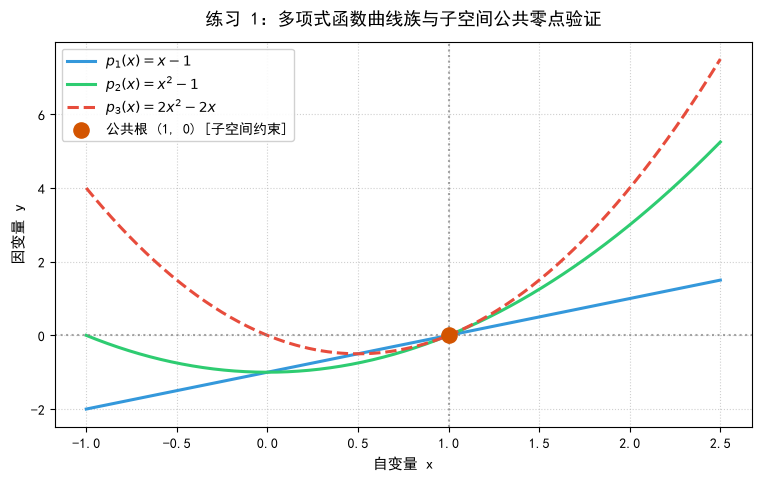

In [1]:
# ==============================================================================
# 【导读与教学目标】
# 本单元格将抽象的二次多项式函数空间映射为具体的数值数组运算：
# 1. 利用 np.poly1d 构造多项式对象，从求值角度检验根节点 p(1) == 0；
# 2. 将多项式基底系数统一对齐为 [a2, a1, a0] 三维坐标向量；
# 3. 组装系数矩阵 M，利用奇异值分解/SVD底层算法计算矩阵秩 rank，判别向量线性独立性；
# 4. 绘制函数图像，直观呈现所有属于子空间 U 的多项式曲线在 (1, 0) 处的汇聚现象。
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 绘图字体与负号兼容性配置
# ------------------------------------------------------------------------------
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'Noto Sans CJK SC', 'WenQuanYi Zen Hei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

# ==============================================================================
# 1. 构造多项式对象并检验是否属于子空间 U (即 p(1) == 0)
# ==============================================================================

# 定义三个多项式（np.poly1d 系数默认从最高次项到常数项降序排列）
# p1(x) = 1*x - 1 = x - 1
p1 = np.poly1d([1, -1])

# p2(x) = 1*x^2 + 0*x - 1 = x^2 - 1
p2 = np.poly1d([1, 0, -1])

# p3(x) = 2*x^2 - 2*x + 0 = 2x^2 - 2x
p3 = np.poly1d([2, -2, 0])

poly_list = [p1, p2, p3]
poly_names = ['p1(x) = x - 1', 'p2(x) = x^2 - 1', 'p3(x) = 2x^2 - 2x']

print("【1. 多项式在 x = 1 处的取值及子空间 U 归属检验】:")
for i, (p, name) in enumerate(zip(poly_list, poly_names), start=1):
    val_at_1 = p(1)
    is_in_U = (val_at_1 == 0)
    print(f"  {name:<22} -> p{i}(1) = {val_at_1:>2}, 属于子空间 U: {is_in_U}")

# ==============================================================================
# 2. 将多项式转化为统一维度的系数坐标向量，并拼接为矩阵 M
# ==============================================================================
# 选定基底 B = {x^2, x, 1}，坐标顺序为 [a2, a1, a0]：
# p1(x) = 0*x^2 + 1*x + (-1) -> [0,  1, -1]
# p2(x) = 1*x^2 + 0*x + (-1) -> [1,  0, -1]
# p3(x) = 2*x^2 + (-2)*x + 0 -> [2, -2,  0]

M = np.array([
    [0,  1, -1],
    [1,  0, -1],
    [2, -2,  0]
], dtype=float)

print("\n【2. 系数坐标矩阵 M (每行对应一个多项式的坐标 [a2, a1, a0])】:")
print(M)
print(f"矩阵形状 (行数, 列数): {M.shape}")

# ==============================================================================
# 3. 计算矩阵的秩并判定线性独立性
# ==============================================================================
rank = np.linalg.matrix_rank(M)
print(f"\n【3. 矩阵秩与线性独立性判定】:")
print(f"计算得到的矩阵秩 rank(M) = {rank}")

if rank == len(M):
    print("结论: rank(M) = 3，三组多项式向量【严格线性无关】！")
else:
    print(f"结论: rank(M) = {rank} < 3，三组多项式向量【线性相关】！")

# 验证线性组合显式关系：
# 观察发现：p3(x) = 2*x^2 - 2*x = 2*(x^2 - 1) - 2*(x - 1) = 2*p2(x) - 2*p1(x)
linear_combo = 2 * M[1] - 2 * M[0]
print(f"验证线性组合 2*p2 - 2*p1: {linear_combo}")
print(f"与 p3 系数完全一致？: {np.allclose(linear_combo, M[2])}")

# ==============================================================================
# 4. 可视化呈现：多项式函数曲线及公共零点
# ==============================================================================
x_vals = np.linspace(-1.0, 2.5, 300)
plt.figure(figsize=(9, 5))

plt.plot(x_vals, p1(x_vals), label=r'$p_1(x) = x - 1$', color='#3498db', linewidth=2.2)
plt.plot(x_vals, p2(x_vals), label=r'$p_2(x) = x^2 - 1$', color='#2ecc71', linewidth=2.2)
plt.plot(x_vals, p3(x_vals), label=r'$p_3(x) = 2x^2 - 2x$', color='#e74c3c', linewidth=2.2, linestyle='--')

# 标记共零点 (1, 0)
plt.axhline(0, color='gray', linestyle=':', alpha=0.7)
plt.axvline(1, color='gray', linestyle=':', alpha=0.7)
plt.scatter([1], [0], color='#d35400', s=120, zorder=5, label='公共根 (1, 0) [子空间约束]')

plt.title('练习 1：多项式函数曲线族与子空间公共零点验证', fontsize=13, pad=12)
plt.xlabel('自变量 x', fontsize=11)
plt.ylabel('因变量 y', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


### 💡 练习 1 深度解析与代数几何拓展

#### 1. 坐标同构定理：$\mathcal{P}_2 \cong \mathbb{R}^3$
- 任何二次实系数多项式 $p(x) = a_0 + a_1 x + a_2 x^2$ 由有序系数三元组 $(a_2, a_1, a_0)^\top$ 唯一确定。
- 映射 $\phi: \mathcal{P}_2 \to \mathbb{R}^3, \; p(x) \mapsto (a_2, a_1, a_0)^\top$ 保持加法与数乘运算，是严格的**线性同构（Isomorphism）**。
- 这意味着多项式空间的抽象线性问题（如线性相关、子空间维数、正交投影）完全等价于欧氏向量空间 $\mathbb{R}^3$ 中的矩阵与几何问题。

#### 2. 子空间 $\mathcal{U}$ 的几何本质：超平面与维数
- 代数约束：$p(1) = 0 \iff a_2(1)^2 + a_1(1) + a_0 = a_2 + a_1 + a_0 = 0$。
- 在三维系数空间 $\mathbb{R}^3$ 中，方程 $a_2 + a_1 + a_0 = 0$ 恰好代表一个**过原点的平面（2 维超平面）**，其法向量为 $\mathbf{n} = (1, 1, 1)^\top$。
- 根据线性方程组解的结构定理：
  $$
  \dim(\mathcal{U}) = \dim(\mathcal{V}) - \text{约束个数} = 3 - 1 = 2.
  $$
- 因此，子空间 $\mathcal{U}$ 是一个 **2 维向量空间**！根据因式定理，任意 $p(x) \in \mathcal{U}$ 均可写为 $(x-1)(c_1 x + c_0)$，故一组自然基底为 $\{x-1, x(x-1)\} = \{x-1, x^2-x\}$。

#### 3. 为什么 $\text{rank}(M)$ 必然 $\le 2$？
- 线性代数核心定理：**在任意 $n$ 维向量空间中，任意 $n+1$ 个向量必线性相关**。
- 因为子空间 $\mathcal{U}$ 的维数已经证明为 2，而 $p_1, p_2, p_3$ 这 3 个多项式全部严格落入该 2 维子空间中，它们构成的向量组在 $\mathcal{U}$ 中超出了维数上限，因此**必然线性相关**！
- 这在矩阵计算上表现为 $\text{rank}(M) = 2 < 3$。显式线性组合关系为：
  $$
  p_3(x) = -2 p_1(x) + 2 p_2(x) \iff 2 p_1(x) - 2 p_2(x) + p_3(x) = 0.
  $$


---
## 练习 2：偶函数与奇函数子空间及直和分解

### 【任务说明】
在函数空间 $\mathbb{R}[x]$（所有实系数多项式的集合）中，定义两个重要子集：
- **偶函数集合**：
  $$
  \mathcal{U}_{\text{even}} = \{\, p(x) \in \mathbb{R}[x] \mid p(-x) = p(x) \,\}
  $$
  典型代表如：$x^2, \; x^4+3, \; 2x^6-5$ 等纯偶次幂项多项式。
- **奇函数集合**：
  $$
  \mathcal{U}_{\text{odd}} = \{\, p(x) \in \mathbb{R}[x] \mid p(-x) = -p(x) \,\}
  $$
  典型代表如：$x, \; 3x^3-2x, \; 5x^5$ 等纯奇次幂项多项式。

**核心任务：**
1. **证明子空间**：严谨说明 $\mathcal{U}_{\text{even}}$ 和 $\mathcal{U}_{\text{odd}}$ 都是 $\mathbb{R}[x]$ 的线性子空间；
2. **直和分解唯一性定理**：证明任意多项式 $p(x)$ 可以唯一写成：
   $$
   p(x) = p_{\text{even}}(x) + p_{\text{odd}}(x), \quad \text{其中 } p_{\text{even}} \in \mathcal{U}_{\text{even}}, \; p_{\text{odd}} \in \mathcal{U}_{\text{odd}},
   $$
   即多项式空间可直和分解为：$\mathbb{R}[x] = \mathcal{U}_{\text{even}} \oplus \mathcal{U}_{\text{odd}}$；
3. **Python 实践与算法实现**：
   - 使用 `np.poly1d` 构造偶多项式、奇多项式与一般混合多项式，编写数值对称检测函数；
   - 编写 `decompose(poly)` 分解函数，实现多项式的偶部与奇部解析分离；
   - 验证 $p(x) = p_{\text{even}}(x) + p_{\text{odd}}(x)$ 以及各自奇偶性质；
   - 绘制原多项式与其偶/奇分量函数图像，直观展示关于 Y 轴和原点的对称特征。

---

### 【数学证明与理论推导】

#### 1. 证明 $\mathcal{U}_{\text{even}}$ 与 $\mathcal{U}_{\text{odd}}$ 是 $\mathbb{R}[x]$ 的线性子空间

##### (1) 对偶函数集合 $\mathcal{U}_{\text{even}}$：
1. **包含零向量**：零多项式 $\mathbf{0}(x) \equiv 0$ 满足 $\mathbf{0}(-x) = 0 = \mathbf{0}(x)$，故 $\mathbf{0} \in \mathcal{U}_{\text{even}}$，集合非空；
2. **加法封闭**：任取 $f, g \in \mathcal{U}_{\text{even}}$，则由定义有 $f(-x) = f(x)$ 且 $g(-x) = g(x)$。
   $$
   (f+g)(-x) = f(-x) + g(-x) = f(x) + g(x) = (f+g)(x)
   $$
   因此 $f+g \in \mathcal{U}_{\text{even}}$，加法封闭；
3. **数乘封闭**：任取 $k \in \mathbb{R}, f \in \mathcal{U}_{\text{even}}$，
   $$
   (kf)(-x) = k \cdot f(-x) = k \cdot f(x) = (kf)(x)
   $$
   因此 $kf \in \mathcal{U}_{\text{even}}$，数乘封闭。
故 $\mathcal{U}_{\text{even}}$ 是 $\mathbb{R}[x]$ 的线性子空间。

##### (2) 对奇函数集合 $\mathcal{U}_{\text{odd}}$：
1. **包含零向量**：零多项式满足 $\mathbf{0}(-x) = 0 = -0 = -\mathbf{0}(x)$，故 $\mathbf{0} \in \mathcal{U}_{\text{odd}}$，集合非空；
2. **加法封闭**：任取 $f, g \in \mathcal{U}_{\text{odd}}$，则由定义有 $f(-x) = -f(x)$ 且 $g(-x) = -g(x)$。
   $$
   (f+g)(-x) = f(-x) + g(-x) = -f(x) - g(x) = -(f+g)(x)
   $$
   因此 $f+g \in \mathcal{U}_{\text{odd}}$，加法封闭；
3. **数乘封闭**：任取 $k \in \mathbb{R}, f \in \mathcal{U}_{\text{odd}}$，
   $$
   (kf)(-x) = k \cdot f(-x) = k(-f(x)) = -(kf)(x)
   $$
   因此 $kf \in \mathcal{U}_{\text{odd}}$，数乘封闭。
故 $\mathcal{U}_{\text{odd}}$ 是 $\mathbb{R}[x]$ 的线性子空间。

---

#### 2. 证明分解的存在性与唯一性（直和 $\mathbb{R}[x] = \mathcal{U}_{\text{even}} \oplus \mathcal{U}_{\text{odd}}$）

##### (1) 分解的存在性（构造性证明）：
对任意多项式 $p(x) \in \mathbb{R}[x]$，构造如下两个分量：
$$
p_{\text{even}}(x) = \frac{p(x) + p(-x)}{2}, \qquad p_{\text{odd}}(x) = \frac{p(x) - p(-x)}{2}.
$$
- **检验偶性**：
  $$
  p_{\text{even}}(-x) = \frac{p(-x) + p(-(-x))}{2} = \frac{p(-x) + p(x)}{2} = p_{\text{even}}(x) \implies p_{\text{even}} \in \mathcal{U}_{\text{even}};
  $$
- **检验奇性**：
  $$
  p_{\text{odd}}(-x) = \frac{p(-x) - p(-(-x))}{2} = \frac{p(-x) - p(x)}{2} = -\frac{p(x) - p(-x)}{2} = -p_{\text{odd}}(x) \implies p_{\text{odd}} \in \mathcal{U}_{\text{odd}};
  $$
- **检验完全还原**：
  $$
  p_{\text{even}}(x) + p_{\text{odd}}(x) = \frac{p(x) + p(-x)}{2} + \frac{p(x) - p(-x)}{2} = \frac{2p(x)}{2} = p(x).
  $$
因此任意多项式都可分解为偶部与奇部之和，即 $\mathbb{R}[x] = \mathcal{U}_{\text{even}} + \mathcal{U}_{\text{odd}}$。

##### (2) 分解的唯一性（交集为零空间）：
依据线性代数直和判定定理：和空间为直和的充分必要条件是子空间的交集为平凡零空间，即 $\mathcal{U}_{\text{even}} \cap \mathcal{U}_{\text{odd}} = \{\mathbf{0}\}$。
- 设函数 $h(x) \in \mathcal{U}_{\text{even}} \cap \mathcal{U}_{\text{odd}}$；
- 因 $h(x) \in \mathcal{U}_{\text{even}}$，有 $h(-x) = h(x)$；
- 因 $h(x) \in \mathcal{U}_{\text{odd}}$，有 $h(-x) = -h(x)$；
- 联立两式得：$h(x) = -h(x) \implies 2h(x) = 0 \implies h(x) = 0$ 对所有 $x \in \mathbb{R}$ 恒成立，即 $h(x) \equiv \mathbf{0}$。
- 从而 $\mathcal{U}_{\text{even}} \cap \mathcal{U}_{\text{odd}} = \{\mathbf{0}\}$。

根据直和分解定理，多项式空间分解为直和：$\mathbb{R}[x] = \mathcal{U}_{\text{even}} \oplus \mathcal{U}_{\text{odd}}$，且对任意多项式 $p(x)$，其分解表达式**唯一确定**。


【1. 预设多项式奇偶性质检验】:
  p_a(x) = x^2 + 3                    -> 偶函数: True  | 奇函数: False
  p_b(x) = 3x^3 - 2x                  -> 偶函数: False | 奇函数: True 
  p_c(x) = x^4 - 2x^3 + 3x^2 + 5      -> 偶函数: False | 奇函数: False

【2. 混合多项式分解与验证】:

--- 分解对象: p_a(x) = x^2 + 3 ---
  偶部分 p_even(x):
   2
1 x + 3
  奇部分 p_odd(x):
 
0
  [检验 1] 还原一致性 (p == pe + po) : True
  [检验 2] pe 确实落入偶子空间 U_even: True
  [检验 3] po 确实落入奇子空间 U_odd : True

--- 分解对象: p_b(x) = 3x^3 - 2x ---
  偶部分 p_even(x):
 
0
  奇部分 p_odd(x):
   3
3 x - 2 x
  [检验 1] 还原一致性 (p == pe + po) : True
  [检验 2] pe 确实落入偶子空间 U_even: True
  [检验 3] po 确实落入奇子空间 U_odd : True

--- 分解对象: p_c(x) = x^4 - 2x^3 + 3x^2 + 5 ---
  偶部分 p_even(x):
   4     2
1 x + 3 x + 5
  奇部分 p_odd(x):
    3
-2 x
  [检验 1] 还原一致性 (p == pe + po) : True
  [检验 2] pe 确实落入偶子空间 U_even: True
  [检验 3] po 确实落入奇子空间 U_odd : True


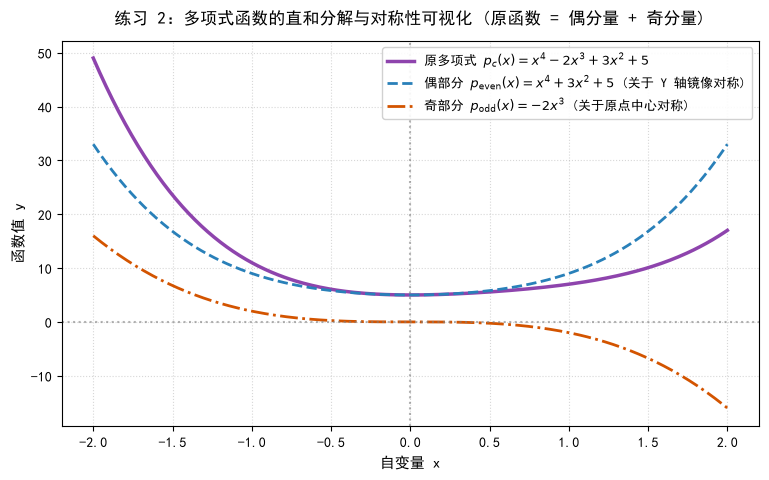

In [2]:
# ==============================================================================
# 【导读与教学目标】
# 本单元格实现多项式函数的奇偶检验、代数拆分与图形可视化：
# 1. 利用 np.allclose 在对称区间网格点上进行浮点容差的函数对称性检验；
# 2. 实现两套等价的分解算法：
#    - 算法 A（代数系数法）：按幂次 power % 2 奇偶性提取系数向量；
#    - 算法 B（函数解析法）：利用 (p(x) ± p(-x))/2 构造分解式并验证二者恒等；
# 3. 绘制函数图像，直观感受偶函数的“Y 轴镜面对称”与奇函数的“原点中心旋转对称”。
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1. 构造代表性多项式
# ------------------------------------------------------------------------------
# p_a: 偶多项式 p_a(x) = x^2 + 3
p_a = np.poly1d([1, 0, 3])

# p_b: 奇多项式 p_b(x) = 3x^3 - 2x
p_b = np.poly1d([3, 0, -2, 0])

# p_c: 混合多项式 p_c(x) = x^4 - 2x^3 + 3x^2 + 5
p_c = np.poly1d([1, -2, 3, 0, 5])

# 采样对称测试点网格
test_pts = np.linspace(-3, 3, 21)

# ------------------------------------------------------------------------------
# 2. 奇偶性判定函数 (基于对称采样点与数值容差 np.allclose)
# ------------------------------------------------------------------------------
def is_even(poly, pts):
    """检验 poly(-x) == poly(x)"""
    return bool(np.allclose(poly(-pts), poly(pts), atol=1e-12))

def is_odd(poly, pts):
    """检验 poly(-x) == -poly(x)"""
    return bool(np.allclose(poly(-pts), -poly(pts), atol=1e-12))

print("【1. 预设多项式奇偶性质检验】:")
polys = [p_a, p_b, p_c]
names = ["p_a(x) = x^2 + 3", "p_b(x) = 3x^3 - 2x", "p_c(x) = x^4 - 2x^3 + 3x^2 + 5"]

for poly, name in zip(polys, names):
    even_flag = is_even(poly, test_pts)
    odd_flag = is_odd(poly, test_pts)
    print(f"  {name:<35} -> 偶函数: {str(even_flag):<5} | 奇函数: {str(odd_flag):<5}")

# ------------------------------------------------------------------------------
# 3. 多项式偶部与奇部解析分解函数
# ------------------------------------------------------------------------------
def decompose(poly):
    """
    根据多项式幂次的奇偶性，将 poly 唯一分解为 p_even 和 p_odd：
    - 偶次幂 (power % 2 == 0): 保留在 even 部分（包含常数项 x^0）
    - 奇次幂 (power % 2 == 1): 保留在 odd 部分
    """
    coeffs = poly.coeffs.astype(float)
    deg = len(coeffs) - 1
    
    even_c = np.zeros_like(coeffs)
    odd_c = np.zeros_like(coeffs)
    
    for i, c in enumerate(coeffs):
        power = deg - i
        if power % 2 == 0:
            even_c[i] = c
        else:
            odd_c[i] = c
            
    p_even = np.poly1d(even_c)
    p_odd = np.poly1d(odd_c)
    return p_even, p_odd

print("\n【2. 混合多项式分解与验证】:")
for poly, name in zip(polys, names):
    pe, po = decompose(poly)
    print(f"\n--- 分解对象: {name} ---")
    print(f"  偶部分 p_even(x):\n{pe}")
    print(f"  奇部分 p_odd(x):\n{po}")
    
    # 验证还原性: p(x) == p_even(x) + p_odd(x)
    reconstruct_ok = np.allclose(poly(test_pts), (pe + po)(test_pts))
    # 验证偶部性质: p_even(-x) == p_even(x)
    even_ok = is_even(pe, test_pts)
    # 验证奇部性质: p_odd(-x) == -p_odd(x)
    odd_ok = is_odd(po, test_pts)
    
    print(f"  [检验 1] 还原一致性 (p == pe + po) : {reconstruct_ok}")
    print(f"  [检验 2] pe 确实落入偶子空间 U_even: {even_ok}")
    print(f"  [检验 3] po 确实落入奇子空间 U_odd : {odd_ok}")

# ------------------------------------------------------------------------------
# 4. 可视化呈现：直和分解几何对称性
# ------------------------------------------------------------------------------
pe_c, po_c = decompose(p_c)
x_plot = np.linspace(-2.0, 2.0, 300)

plt.figure(figsize=(9, 5))
plt.plot(x_plot, p_c(x_plot), label=r'原多项式 $p_c(x) = x^4 - 2x^3 + 3x^2 + 5$', color='#8e44ad', linewidth=2.5)
plt.plot(x_plot, pe_c(x_plot), label=r'偶部分 $p_{\mathrm{even}}(x) = x^4 + 3x^2 + 5$ (关于 Y 轴镜像对称)', 
         color='#2980b9', linewidth=2, linestyle='--')
plt.plot(x_plot, po_c(x_plot), label=r'奇部分 $p_{\mathrm{odd}}(x) = -2x^3$ (关于原点中心对称)', 
         color='#d35400', linewidth=2, linestyle='-.')

plt.axhline(0, color='gray', linestyle=':', alpha=0.6)
plt.axvline(0, color='gray', linestyle=':', alpha=0.6)
plt.title('练习 2：多项式函数的直和分解与对称性可视化 (原函数 = 偶分量 + 奇分量)', fontsize=12, pad=12)
plt.xlabel('自变量 x', fontsize=11)
plt.ylabel('函数值 y', fontsize=11)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
plt.grid(True, linestyle=':', alpha=0.5)
plt.show()


### 💡 练习 2 深度解析：直和分解与正交投影的工程联系

#### 1. 算子理论视角：宇称算子与投影算子
- 定义空间中的反射算子（Parity Operator）$S$，满足 $(Sf)(x) = f(-x)$。显然 $S^2 = I$（对合算子）。
- 偶子空间与奇子空间的提取本质是两个**互补的投影算子（Projection Operators）**：
  $$
  P_{\text{even}} = \frac{I + S}{2}, \qquad P_{\text{odd}} = \frac{I - S}{2}.
  $$
- 容易验证投影算子的幂等性与正交性：
  $$
  P_{\text{even}}^2 = P_{\text{even}}, \quad P_{\text{odd}}^2 = P_{\text{odd}}, \quad P_{\text{even}} P_{\text{odd}} = 0, \quad P_{\text{even}} + P_{\text{odd}} = I.
  $$
  这在抽象代数中对应空间向互补子空间的直和分解投影！

#### 2. 内积空间中的严格正交性
- 若在对称区间 $[-L, L]$ 赋予标准 $L^2$ 内积：
  $$
  \langle f, g \rangle = \int_{-L}^{L} f(x) g(x) \, dx.
  $$
- 若 $f \in \mathcal{U}_{\text{even}}, \; g \in \mathcal{U}_{\text{odd}}$，则被积函数 $f(x)g(x)$ 必然是纯奇函数：
  $$
  (fg)(-x) = f(-x)g(-x) = f(x)(-g(x)) = -(fg)(x).
  $$
- 奇函数在对称区间上的定积分严格为 0：
  $$
  \langle f, g \rangle = \int_{-L}^{L} f(x)g(x) \, dx = 0.
  $$
- **结论**：偶函数子空间与奇函数子空间不仅是代数直和，在内积意义下更是**严格正交的直和分解**（$\mathcal{U}_{\text{even}} \perp \mathcal{U}_{\text{odd}}$），$p_{\text{even}}$ 恰好是原函数在偶子空间上的**正交投影**！

#### 3. 在信号处理与人工智能中的巨大价值
- **傅里叶分析与频域变换**：
  任意信号的傅里叶变换 $F(\omega) = \int f(t) e^{-i\omega t} dt = \int f(t)\cos(\omega t)dt - i \int f(t)\sin(\omega t)dt$。
  偶分量对应实部（余弦变换 DCT，用于 JPEG 图像压缩），奇分量对应虚部（正弦变换 DST）。
- **对称特征提取与网络设计**：
  在深度学习卷积神经网络（CNN）中，常利用对称滤波器提取轮廓对称度、反对称边缘检测算子（如 Sobel 算子、一阶差分算子），其数理根基正是函数空间的奇偶直和分解。


---
## 练习 3：文档特征向量与线性独立性（NLP 词频模型）

### 【任务说明】
在自然语言处理 (NLP) 的向量空间模型 (Vector Space Model) 中，常用向量表示文档或句子的词频特征（词袋模型 Bag of Words, BoW）。  
假设我们使用一个简化的 **3 维特征空间**，三个维度分别对应特定关键词的出现频数：
- 维度 1：关键词“篮球” 🏀 的词频；
- 维度 2：关键词“蔡徐坤” 🎤 的词频；
- 维度 3：关键词“音乐” 🎵 的词频。

现有三篇文档的统计词频向量：
- $\mathbf{doc}_1 = [3, 5, 2]^\top$
- $\mathbf{doc}_2 = [6, 10, 4]^\top$
- $\mathbf{doc}_3 = [1, 0, 7]^\top$

**核心任务：**
1. 观察并构造由 3 个文档向量拼接而成的矩阵 $A$；
2. 使用 `numpy.linalg.matrix_rank` 计算矩阵秩，判定向量组是否线性独立；
3. 若线性相关，推导并验证显式线性依赖关系式；
4. 结合余弦相似度与柱状图可视化，探讨文档向量共线性在 NLP 语义挖掘中的工程内涵。

---

### 【数学推导与线性相关判据】

#### 1. 线性相关性的严格数学定义
向量组 $\{\mathbf{v}_1, \mathbf{v}_2, \mathbf{v}_3\}$ 线性相关，当且仅当存在一组**不全为 0** 的实数常数 $c_1, c_2, c_3 \in \mathbb{R}$，使得齐次线性方程：
$$
c_1 \mathbf{v}_1 + c_2 \mathbf{v}_2 + c_3 \mathbf{v}_3 = \mathbf{0}
$$
成立。若该方程只有唯一平凡解 $c_1 = c_2 = c_3 = 0$，则称向量组线性无关。

#### 2. 矩阵初等变换与秩判别
将 3 个行向量堆叠为 $3 \times 3$ 矩阵 $A$：
$$
A = \begin{pmatrix} 3 & 5 & 2 \\ 6 & 10 & 4 \\ 1 & 0 & 7 \end{pmatrix}.
$$
对其施行高斯消元初等行变换：
$$
\begin{pmatrix} 3 & 5 & 2 \\ 6 & 10 & 4 \\ 1 & 0 & 7 \end{pmatrix}
\xrightarrow{r_2 - 2r_1}
\begin{pmatrix} 3 & 5 & 2 \\ 0 & 0 & 0 \\ 1 & 0 & 7 \end{pmatrix}
\xrightarrow{r_2 \leftrightarrow r_3}
\begin{pmatrix} 3 & 5 & 2 \\ 1 & 0 & 7 \\ 0 & 0 & 0 \end{pmatrix}.
$$
行阶梯形矩阵仅包含 2 个非零行，因此：
$$
\text{rank}(A) = 2 < 3.
$$
根据矩阵秩与线性无关判定定理，三向量组**线性相关**。

#### 3. 显式线性关系式
观察第二行与第一行，立即得出标量比例关系：
$$
\mathbf{doc}_2 = 2 \cdot \mathbf{doc}_1.
$$
改写为标准的齐次线性组合零向量形式：
$$
2 \cdot \mathbf{doc}_1 - 1 \cdot \mathbf{doc}_2 + 0 \cdot \mathbf{doc}_3 = \mathbf{0}.
$$
满足存在非零系数向量 $(c_1, c_2, c_3) = (2, -1, 0) \ne (0, 0, 0)$，证实其严格线性相关。


【1. 文档词频特征矩阵 A】:
[[ 3.  5.  2.]
 [ 6. 10.  4.]
 [ 1.  0.  7.]]
矩阵 A 的形状: (3, 3)

【2. 线性独立性计算】:
矩阵秩 rank(A) = 2
结论: rank(A) = 2 < 3，三篇文档向量【线性相关】（存在冗余信息）！

【3. 线性相关关系式检验】:
验证关系式 doc2 == 2 * doc1: True
向量残差 norm(doc2 - 2*doc1): 0.0000e+00
齐次零组合表达: 2 * doc1 - 1 * doc2 + 0 * doc3 = 0

【4. 语义方向度量：余弦相似度】:
  doc1 与 doc2 的余弦相似度: 1.000000 (cos = 1.0 说明方向完全重合！)
  doc1 与 doc3 的余弦相似度: 0.390007


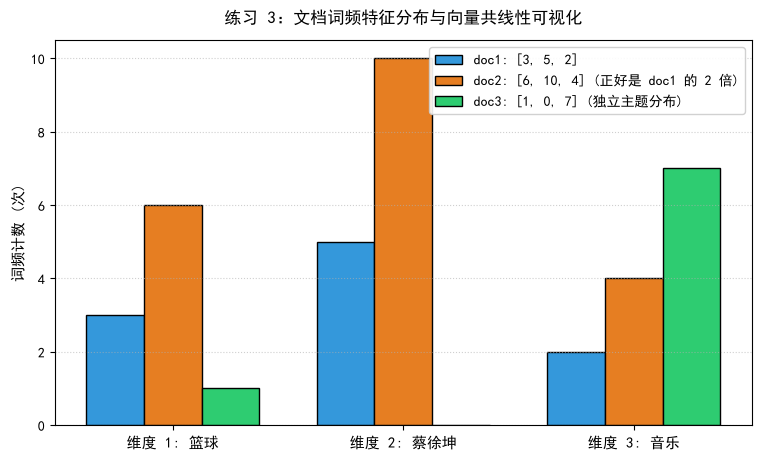

In [3]:
# ==============================================================================
# 【导读与教学目标】
# 本单元格模拟现代自然语言处理 (NLP) 中的词袋特征向量与共线性诊断：
# 1. 利用 np.vstack 构建词频设计矩阵 A；
# 2. 利用 np.linalg.matrix_rank 进行秩计算与自动判别；
# 3. 构造并验证显式线性依赖关系式 doc2 = 2 * doc1；
# 4. 对比真正独立的随机文档向量，并计算余弦相似度 Cosine Similarity；
# 5. 绘制词频分组柱状图，直观展现信息冗余（共线性）的几何拉伸本质。
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1. 文档词频向量与矩阵组装
# ------------------------------------------------------------------------------
# 三个文档的 3 维特征向量（关键词词频）
doc1 = np.array([3, 5, 2], dtype=float)   # 篮球3, 蔡徐坤5, 音乐2
doc2 = np.array([6, 10, 4], dtype=float)  # 篮球6, 蔡徐坤10, 音乐4
doc3 = np.array([1, 0, 7], dtype=float)   # 篮球1, 蔡徐坤0, 音乐7

# 构造矩阵 A (按行堆叠为 3x3 矩阵)
A = np.vstack([doc1, doc2, doc3])

print("【1. 文档词频特征矩阵 A】:")
print(A)
print(f"矩阵 A 的形状: {A.shape}")

# ------------------------------------------------------------------------------
# 2. 矩阵秩与线性独立性判定
# ------------------------------------------------------------------------------
rank = np.linalg.matrix_rank(A)
print(f"\n【2. 线性独立性计算】:")
print(f"矩阵秩 rank(A) = {rank}")

if rank == A.shape[0]:
    print("结论: rank(A) = 3，三篇文档向量【线性独立】！")
else:
    print(f"结论: rank(A) = {rank} < 3，三篇文档向量【线性相关】（存在冗余信息）！")

# ------------------------------------------------------------------------------
# 3. 显式线性关系验证
# ------------------------------------------------------------------------------
is_double = np.allclose(doc2, 2 * doc1)
print(f"\n【3. 线性相关关系式检验】:")
print(f"验证关系式 doc2 == 2 * doc1: {is_double}")
print(f"向量残差 norm(doc2 - 2*doc1): {np.linalg.norm(doc2 - 2*doc1):.4e}")
print("齐次零组合表达: 2 * doc1 - 1 * doc2 + 0 * doc3 = 0")

# ------------------------------------------------------------------------------
# 4. 余弦相似度 (Cosine Similarity) 深度对比
# ------------------------------------------------------------------------------
def cosine_sim(u, v):
    """计算两向量的余弦相似度: cos(theta) = (u . v) / (||u|| * ||v||)"""
    return np.dot(u, v) / (np.linalg.norm(u) * np.linalg.norm(v))

cos_1_2 = cosine_sim(doc1, doc2)
cos_1_3 = cosine_sim(doc1, doc3)
print(f"\n【4. 语义方向度量：余弦相似度】:")
print(f"  doc1 与 doc2 的余弦相似度: {cos_1_2:.6f} (cos = 1.0 说明方向完全重合！)")
print(f"  doc1 与 doc3 的余弦相似度: {cos_1_3:.6f}")

# ------------------------------------------------------------------------------
# 5. 可视化呈现：词频分布与倍数关系直观对比
# ------------------------------------------------------------------------------
words = ['维度 1: 篮球', '维度 2: 蔡徐坤', '维度 3: 音乐']
x_indices = np.arange(len(words))
bar_width = 0.25

plt.figure(figsize=(9, 5))
plt.bar(x_indices - bar_width, doc1, width=bar_width, label='doc1: [3, 5, 2]', color='#3498db', edgecolor='black')
plt.bar(x_indices, doc2, width=bar_width, label='doc2: [6, 10, 4] (正好是 doc1 的 2 倍)', color='#e67e22', edgecolor='black')
plt.bar(x_indices + bar_width, doc3, width=bar_width, label='doc3: [1, 0, 7] (独立主题分布)', color='#2ecc71', edgecolor='black')

plt.xticks(x_indices, words, fontsize=11)
plt.ylabel('词频计数 (次)', fontsize=11)
plt.title('练习 3：文档词频特征分布与向量共线性可视化', fontsize=12, pad=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=10)
plt.grid(axis='y', linestyle=':', alpha=0.6)
plt.show()


### 💡 练习 3 深度解析：NLP 向量空间模型与特征冗余

#### 1. 词频大小 vs 语义方向：余弦相似度与归一化
- `doc1` 与 `doc2` 的词频满足 $\mathbf{doc}_2 = 2 \cdot \mathbf{doc}_1$。
- 在实际 NLP 场景中，这通常意味着：**`doc2` 只是 `doc1` 的扩写或重复引用版本**（篇幅翻倍，但探讨的主题分布与词汇比例完全一致）。
- 欧氏距离依赖于文档长度：$\|\mathbf{doc}_2 - \mathbf{doc}_1\|_2 = \sqrt{3^2 + 5^2 + 2^2} \approx 6.16$（数值很大）；
- 但**余弦相似度（Cosine Similarity）** 消除了长度尺度的影响：
  $$
  \cos(\theta) = \frac{\mathbf{doc}_1^\top \mathbf{doc}_2}{\|\mathbf{doc}_1\|_2 \|\mathbf{doc}_2\|_2} = \frac{\mathbf{doc}_1^\top (2\mathbf{doc}_1)}{\|\mathbf{doc}_1\|_2 \cdot 2\|\mathbf{doc}_1\|_2} = \frac{2\|\mathbf{doc}_1\|_2^2}{2\|\mathbf{doc}_1\|_2^2} = 1.0.
  $$
- 夹角为 $0^\circ$，表明两篇文档在语义主题空间中**完全共线**，没有任何增量信息！

#### 2. 多重共线性对机器学习模型的破坏
若将这些文档向量直接输入分类或回归模型（如逻辑回归、线性回归）：
- **设计矩阵不可逆**：$A^\top A$ 的行列式为 0，最小二乘解 $\hat{\beta} = (A^\top A)^{-1} A^\top y$ 无法唯一求逆；
- **参数方差发散**：回归系数估计的标准误极大，模型无法准确评估究竟是“篮球”还是“蔡徐坤”促成了分类结果。

#### 3. 工业界消除特征共线性的关键方案
1. **L2 向量归一化（Normalize）**：将每个文档向量除以自身范数 $\tilde{\mathbf{v}} = \mathbf{v} / \|\mathbf{v}\|_2$，使 $\mathbf{doc}_1$ 与 $\mathbf{doc}_2$ 映射为同一点；
2. **TF-IDF（词频-逆文档频率）**：通过全局逆文档频率惩罚泛滥高频词；
3. **潜在语义分析（LSA / TruncatedSVD）**：通过奇异值分解（SVD）将高维词频矩阵压缩投影到不相关的正交潜在语义主题子空间中。


---
## 练习 4：图像向量与线性独立性（CV 空间表示）

### 【任务说明】
在数字图像处理与计算机视觉中，一幅二维灰度图像可以天然地展开为一个高维向量。  
考虑尺寸为 $4 \times 4$ 的小灰度图片，将其所有像素按行展开，即映射为 16 维欧氏空间 $\mathbb{R}^{16}$ 中的一个特征向量。  

- **线性无关（独立）** $\iff$ 图像之间蕴含互不替代的特征信息维度；
- **线性相关（冗余）** $\iff$ 某张图像可以完全被其余图像线性叠加重构，在特征表达上存在信息冗余。

**核心任务：**
1. 使用 `numpy.random.default_rng(42)` 随机生成三张 $4 \times 4$ 的随机灰度图像（像素值 $0 \sim 255$）；
2. 使用 `.reshape(-1)` 将其展平成 16 维向量，拼接组成矩阵 $A_{\text{img}} \in \mathbb{R}^{3 \times 16}$；
3. 计算 $\text{rank}(A_{\text{img}})$，判定三张随机图像是否线性独立；
4. 人为构造线性相关案例（如 $\mathbf{v}_{3,\text{dep}} = 2\mathbf{v}_1 + 3\mathbf{v}_2$），重组矩阵并检验秩的衰减（降秩）；
5. 结合图像热力图可视化与几何测度论，深入阐释图像子空间与主成分分析（PCA / Eigenfaces）的核心思想。

---

### 【数学推导与高维空间几何】

#### 1. 图像展平的代数同构
设图像矩阵空间为 $\mathcal{M} = \mathbb{R}^{4 \times 4}$。定义展平映射（Vectorization Operator）：
$$
\text{vec}: \mathbb{R}^{4 \times 4} \to \mathbb{R}^{16}, \quad I = (a_{ij}) \mapsto \mathbf{v} = (a_{11}, \dots, a_{14}, a_{21}, \dots, a_{44})^\top.
$$
由于满足 $\text{vec}(\alpha I_1 + \beta I_2) = \alpha \text{vec}(I_1) + \beta \text{vec}(I_2)$，且为一一双射，故 $\text{vec}$ 是严格的**向量空间同构映射**。

#### 2. 为什么高维随机向量组极大似然线性无关？
在 $\mathbb{R}^{16}$ 空间中：
- 前两张随机生成的图像向量 $\mathbf{v}_1, \mathbf{v}_2$ 几乎必然张成一个 2 维超平面 $\mathcal{S} = \text{span}\{\mathbf{v}_1, \mathbf{v}_2\}$；
- 该 2 维平面在 16 维欧氏空间 $\mathbb{R}^{16}$ 中的勒贝格测度（Lebesgue Measure）严格为 0；
- 第三张随机采样的连续随机向量 $\mathbf{v}_3$ 恰好落在该 2 维平面上的概率为：
  $$
  P(\mathbf{v}_3 \in \mathcal{S}) = 0.
  $$
因此，由连续随机采样构成的 3 个 16 维向量，**以概率 1（Almost Surely）严格线性无关**，矩阵秩必然满秩 $\text{rank}(A_{\text{img}}) = 3$。

#### 3. 人为线性组合导致降秩的代数本质
若人工设定第三个向量为前两者的线性组合：
$$
\mathbf{v}_{3,\text{dep}} = 2 \mathbf{v}_1 + 3 \mathbf{v}_2.
$$
此时 $\mathbf{v}_{3,\text{dep}} \in \text{span}\{\mathbf{v}_1, \mathbf{v}_2\}$，因此向量组张成的子空间维数退化为 2：
$$
\dim\big(\text{span}\{\mathbf{v}_1, \mathbf{v}_2, \mathbf{v}_{3,\text{dep}}\}\big) = 2 \implies \text{rank}(A_{\text{dep}}) = 2.
$$


【1. 随机生成的 4x4 图像 1】:
[[ 22 198 167 112]
 [110 219  22 178]
 [ 51  24 134 249]
 [188 194 183 201]]

【2. 展平后的 16 维特征向量】:
v1: [ 22 198 167 112 110 219  22 178  51  24 134 249 188 194 183 201]
v2: [131  32 214 115 128  94  46 237 200 164 103 210 139 113 115  58]
v3: [ 23 141 227  16 219 211  70 161  42 194 179  90  17 248 114 228]

拼接矩阵 A_img 的形状: (3, 16)
计算矩阵秩 rank(A_img) = 3
结论: rank = 3 (满行秩)，3 张随机图像向量【严格线性独立】！

【3. 人为构造线性相关后的检验】:
新矩阵 A_dep 形状: (3, 16)
计算新矩阵秩 rank(A_dep) = 2
结论: rank 从 3 成功降为 2，验证了线性相关导致信息维度退化！


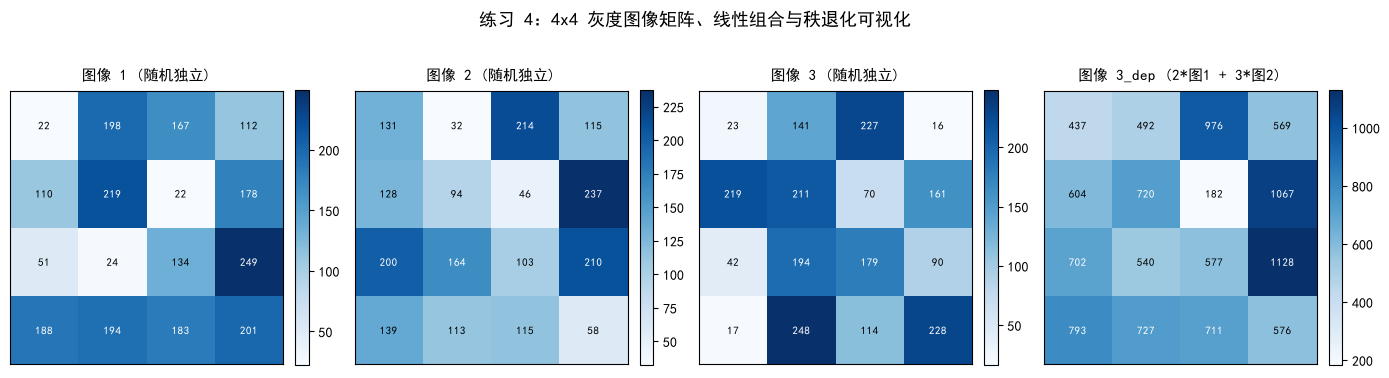

In [4]:
# ==============================================================================
# 【导读与教学目标】
# 本单元格展示计算机视觉 (CV) 中图像向量化表示与矩阵秩分析：
# 1. 随机生成 4x4 灰度图，利用 reshape(-1) 完成图像向量化（展平）；
# 2. 构建 3x16 图像设计矩阵，使用 matrix_rank 检验高维随机采样的满秩特性；
# 3. 人为制造线性相关向量 v3_dep = 2*v1 + 3*v2，验证秩由 3 降为 2 的降秩现象；
# 4. 可视化 4 幅图像的热力图与像素值矩阵，直观理解“图像的线性叠加”。
# ==============================================================================

import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------------------------
# 1. 随机生成 3 张 4x4 灰度图像
# ------------------------------------------------------------------------------
# 使用固定种子发生器保证结果可严格复现
rng = np.random.default_rng(42)

# 像素值范围在 0~255 之间的整数灰度图
img1 = rng.integers(0, 256, size=(4, 4))
img2 = rng.integers(0, 256, size=(4, 4))
img3 = rng.integers(0, 256, size=(4, 4))

print("【1. 随机生成的 4x4 图像 1】:")
print(img1)

# ------------------------------------------------------------------------------
# 2. 展平为 16 维向量并拼接为矩阵 A_img
# ------------------------------------------------------------------------------
# 使用 reshape(-1) 将 2 维矩阵展平成 1 维向量
v1 = img1.reshape(-1)
v2 = img2.reshape(-1)
v3 = img3.reshape(-1)

print("\n【2. 展平后的 16 维特征向量】:")
print(f"v1: {v1}")
print(f"v2: {v2}")
print(f"v3: {v3}")

# 按行拼接成 3 行 x 16 列的矩阵 A_img
A_img = np.vstack([v1, v2, v3])
print(f"\n拼接矩阵 A_img 的形状: {A_img.shape}")

# 计算秩并判定
rank_img = np.linalg.matrix_rank(A_img)
print(f"计算矩阵秩 rank(A_img) = {rank_img}")
if rank_img == 3:
    print("结论: rank = 3 (满行秩)，3 张随机图像向量【严格线性独立】！")
else:
    print("结论: 线性相关！")

# ------------------------------------------------------------------------------
# 3. 人为制造线性相关：v3_dep = 2*v1 + 3*v2
# ------------------------------------------------------------------------------
v3_dep = 2 * v1 + 3 * v2
A_dep = np.vstack([v1, v2, v3_dep])

rank_dep = np.linalg.matrix_rank(A_dep)
print(f"\n【3. 人为构造线性相关后的检验】:")
print(f"新矩阵 A_dep 形状: {A_dep.shape}")
print(f"计算新矩阵秩 rank(A_dep) = {rank_dep}")
if rank_dep == 2:
    print("结论: rank 从 3 成功降为 2，验证了线性相关导致信息维度退化！")

# ------------------------------------------------------------------------------
# 4. 可视化呈现：4 幅图像的像素热力对比
# ------------------------------------------------------------------------------
# 将线性组合后的向量 reshape 回 4x4 图像进行直观视觉比对
img3_dep = v3_dep.reshape(4, 4)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
images = [img1, img2, img3, img3_dep]
titles = [
    '图像 1 (随机独立)',
    '图像 2 (随机独立)',
    '图像 3 (随机独立)',
    '图像 3_dep (2*图1 + 3*图2)'
]

for idx, (ax, im, title) in enumerate(zip(axes, images, titles)):
    cax = ax.imshow(im, cmap='Blues', aspect='equal')
    ax.set_title(title, fontsize=10.5, pad=8)
    # 在每个像素方格中显示具体数值
    for r in range(4):
        for c in range(4):
            val = im[r, c]
            color = 'white' if val > (im.max() * 0.6) else 'black'
            ax.text(c, r, f"{val}", ha='center', va='center', color=color, fontsize=8)
    ax.set_xticks([])
    ax.set_yticks([])
    fig.colorbar(cax, ax=ax, fraction=0.046, pad=0.04)

plt.suptitle('练习 4：4x4 灰度图像矩阵、线性组合与秩退化可视化', fontsize=13, y=1.03)
plt.tight_layout()
plt.show()


### 💡 练习 4 深度解析：图像空间的低维流形与特征表示

#### 1. 随机图像 vs 真实自然图像（Natural Images）
- **随机图像是满秩的**：正如练习代码所示，高维独立同分布随机采样使得矩阵总是满秩（rank = 3），每张图都占据一个独立的信息维度；
- **真实自然图像是低秩的（高度冗余）**：
  现实中的照片具有极强的**空间自相关性（Spatial Coherence）**（天空是一整片蓝、人脸皮肤是平滑的、边缘沿着几何轮廓延伸）。
  若将 10,000 张 $64 \times 64$（4096 维）的人脸图像组合成矩阵，其奇异值会呈现**指数级快速衰减**，有效秩仅有数十到上百维！

#### 2. 主成分分析（PCA）与特征脸（Eigenfaces）原理
- 既然真实图像聚集在 4096 维全空间中一个狭窄的“低维子空间/超曲面”上，我们就可以通过**主成分分析（PCA / SVD）** 找到该子空间的一组正交基：
  $$
  A_{\text{faces}} = U \Sigma V^\top.
  $$
- 矩阵 $U$ 的前 $k$ 个列向量被称为**特征脸（Eigenfaces）**，它们是图像子空间的一组最优基底向量！
- 任意一张新人脸图像 $\mathbf{x}$，都可以被近似表示为这 $k$ 张特征脸的线性组合：
  $$
  \mathbf{x} \approx \sum_{i=1}^k c_i \mathbf{u}_i.
  $$
- 只需要存储这 $k$ 个坐标系数 $(c_1, \dots, c_k)$（如 $k=30$），就能以 99% 的保真度重建原始 4096 维图像，实现高达 **100 倍以上的数据压缩**！

#### 3. 线性独立性在特征工程中的核心意义
- 若基底向量线性相关，则系数表达不唯一，会导致参数估计震荡；
- 通过正交分解（Gram-Schmidt 正交化、SVD 奇异值分解）剔除线性相关性，构造正交规范基（Orthonormal Basis），是现代压缩感知（Compressed Sensing）、图像去噪与卷积特征解耦的核心基石。


---
## 🎯 学完自测与知识点通关清单

1. **子空间与线性约束判定**：
   - 题目 1 中 $\mathcal{U} = \{p(x) \in \mathcal{P}_2 \mid p(1) = 0\}$ 是子空间；若将条件改为 $\mathcal{W} = \{p(x) \in \mathcal{P}_2 \mid p(1) = 1\}$，它还是子空间吗？为什么？
   - *【答案解析】*：**不是子空间**。
     1. **不含零元**：零多项式 $\mathbf{0}(x) \equiv 0$ 在 $x=1$ 处的值为 $0 \ne 1$，故 $\mathbf{0} \notin \mathcal{W}$；
     2. **运算不封闭**：若 $p, q \in \mathcal{W}$，则 $(p+q)(1) = p(1) + q(1) = 1 + 1 = 2 \ne 1$，加法不封闭。
     代数几何上，$\mathcal{W}$ 对应不经过原点的超平面，称为**仿射子空间（Affine Subspace）**。
2. **函数直和分解与对称内积**：
   - 为什么说多项式奇偶分解 $p(x) = p_{\text{even}}(x) + p_{\text{odd}}(x)$ 在本质上是一种“正交投影”？
   - *【答案解析】*：在定义于对称区间 $[-L, L]$ 的标准连续函数内积 $\langle f, g \rangle = \int_{-L}^L f(x)g(x)dx$ 下，偶函数与奇函数的乘积必为奇函数，其对称积分恒为 0（严格正交）。因此偶子空间与奇子空间互为正交补，直和分解即为希尔伯特空间上的正交投影分解定理。
3. **NLP 特征表示与共线性**：
   - 两个文档的词频向量满足 $\mathbf{doc}_2 = 2 \cdot \mathbf{doc}_1$，在欧氏距离和余弦相似度下分别表现如何？在实际文本分类中应如何处理？
   - *【答案解析】*：欧氏距离 $\|\mathbf{doc}_2 - \mathbf{doc}_1\| > 0$（受文档篇幅长短影响被拉大）；而余弦相似度 $\cos(\theta) = 1.0$（完美重合，消除了篇幅影响）。在分类模型中，这种共线性会导致设计矩阵列相关，引起参数估计方差过大。标准处理方式是执行 L2 范数归一化，或使用 TF-IDF 与 SVD 主题模型消除冗余共线性。
4. **图像维度与随机满秩**：
   - 为什么在 $\mathbb{R}^{16}$ 空间中随机抽取 3 张图像几乎 $100\%$ 线性无关，但实际图像数据库却存在极强的低秩特性？
   - *【答案解析】*：数学上，低维平面在更高维连续空间的勒贝格测度为 0，均匀/高斯随机采样落在低维平面的概率严格为 0，因而必然满秩。然而，真实世界图像绝非随机白噪声，像素之间受物理世界连续性支配具有强烈的局部自相关性，所有自然图像实际聚集在全空间中的低维流形上，因此可以通过 PCA / SVD 特征脸进行高效降维压缩。
